# 決策樹圖解：ML 慢慢學 EP07 的程式

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ntanh-ml/ml-manmanxue/blob/main/v08-decision-tree/notebook.ipynb)

這本 notebook 產生影片裡焚化爐範例的**每一張資料圖和每一個數字**。所有資料都是**模擬資料，非實廠數據**，不代表任何一座真實焚化廠。
This notebook generates every chart and number of the incinerator example in EP07 of the YouTube channel ML 慢慢學 (https://www.youtube.com/@ml-step-by-step). All data are **simulated** and do not describe any real plant.

題目和 EP05、EP06 一樣：每一分鐘判斷「接下來一小時的一氧化碳（CO）平均，會不會超過廠內自訂的警戒值 30 ppm」。
EP05 用的是一條**加權公式**（邏輯斯迴歸）。這一集改用**決策樹**：一次問一題「某個感測器有沒有小於某個值」，下一題問什麼看上一題的答案，最後走到一片**葉子**，葉子給一個機率。

| 段落 | 對應影片 |
|---|---|
| 1. 重建 EP05 的資料和模型（一個數字都不改） | 第 2 段 |
| 2. 一個問題 = 一個感測器 + 一個切點：把資料分成兩群 | 第 3 段 |
| 3. 先問哪一題：用熵（就是 EP05 的交叉熵）挑問題 | 第 4 段 |
| 4. 一直問下去：長出一棵樹 | 第 5 段 |
| 5. （Colab 才跑）和 scikit-learn 對照 | — |
| 6. 樹太深會背答案：用驗證集選深度 | 第 6 段 |
| 7. 讀得懂的規則 | 第 7 段 |
| 8. 用 EP06 的規則選門檻（樹和 EP05 的模型各選各的） | 第 8 段 |
| 9. 少一天資料，樹會不會變？ | 第 9 段 |
| 10. 鎖定設定（之後不再改） | — |
| 11. 測試集：全新的 40 天，只評估這一次 | 第 8 段 |
| 12. 匯出資料給影片使用 | — |

**流程紀律**：深度和門檻都只用驗證集、照事先寫好的規則選。測試集在第 10 段鎖定之後才產生，只評估一次。EP05、EP06 用過的模擬種子（2026、2028、2029–2045）這一集都不拿來評分。

**單位**：模型每一分鐘判斷一次，所以「次數」都是**分鐘數**。相鄰的分鐘答案幾乎一樣（都在看重疊的 60 分鐘），所以 5,700 分鐘不等於 5,700 個互相獨立的例子。

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager

PAPER, INK, RED, BLUE, AMBER, TEAL, GREY = "#F6F1E7", "#3B2F2A", "#D8573C", "#4FA3D1", "#D79A2B", "#2A9D8F", "#9A8F86"
LABEL = "模擬資料，非實廠數據"

# Chinese font for the plots. Uses LXGW WenKai TC (OFL) if present; otherwise Noto Sans CJK.
# On Google Colab the Noto CJK font is installed automatically so the Chinese labels display correctly.
import subprocess, sys
FONT = Path("../../tools/fonts/LXGWWenKaiTC-Medium.ttf")
CJK = Path("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc")
if not FONT.exists() and not CJK.exists() and "google.colab" in sys.modules:
    print("正在安裝中文字型（約 30 秒）…")
    if subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-noto-cjk"]).returncode != 0:
        subprocess.run(["apt-get", "-qq", "update"])
        subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-noto-cjk"])
for f in (FONT, CJK):
    if f.exists():
        font_manager.fontManager.addfont(str(f))
        plt.rcParams["font.family"] = font_manager.FontProperties(fname=str(f)).get_name()
        break
plt.rcParams.update({"figure.facecolor": PAPER, "axes.facecolor": PAPER, "axes.edgecolor": INK,
                     "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "text.color": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110,
                     "axes.unicode_minus": False})

def tag(ax):
    ax.text(0.99, 0.97, LABEL, transform=ax.transAxes, ha="right", va="top", fontsize=8, color=RED)

def sigmoid(z): return 1.0 / (1.0 + np.exp(-z))

def cross_entropy(y, p):
    # 和 EP05、EP06 同一個函式：機率夾在 1e-12 和 1 − 1e-12 之間，避免 log(0)
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return float(-(y * np.log(p) + (1 - y) * np.log(1 - p)).mean())

## 1. 重建 EP05 的資料和模型（一個數字都不改）
模擬方式、亂數種子、訓練集（第 1–10 天）、驗證集（第 11–14 天）、梯度下降的設定，全部和 EP05 notebook 相同。
最後核對：重建出來的權重必須和 EP05 匯出的 `v06.json` 一致。EP05 的模型在這一集是**對照組**。

In [2]:
def lag(x, tau):
    y = np.empty_like(x); y[0] = x[0]
    for i in range(1, len(x)):
        y[i] = y[i - 1] + (x[i] - y[i - 1]) / tau
    return y

CO_BASE, CO_SMAX = 14.0, 1.5
A_O2, A_TEMP = 1.8, 0.2
TAU_U, SD_U = 40, 0.3

def simulate(seed, days):
    # 和 EP05 notebook 第 1 段完全相同
    rng = np.random.default_rng(seed)
    N = days * 1440
    MU, SD = 2050.0, 150.0
    PHI = np.exp(-1 / 120)
    lhv = np.empty(N); lhv[0] = MU
    noise = rng.normal(0, SD * np.sqrt(1 - PHI ** 2), N)
    for i in range(1, N):
        lhv[i] = MU + PHI * (lhv[i - 1] - MU) + noise[i]
    lhv = np.clip(lhv, 1500, 2500)
    F_set = np.empty(N); i, level = 0, 12.5
    while i < N:
        length = int(rng.integers(120, 360))
        level = float(np.clip(level + rng.normal(0, 0.7), 10.5, 14.5))
        F_set[i:i + length] = level; i += length
    feed = lag(F_set, 15) + rng.normal(0, 0.15, N)
    trim = np.empty(N); trim[0] = 0.0
    PT = np.exp(-1 / 180)
    e_trim = rng.normal(0, 0.06 * np.sqrt(1 - PT ** 2), N)
    for i in range(1, N):
        trim[i] = PT * trim[i - 1] + e_trim[i]
    air = lag(3000 * F_set * (1 + trim), 5) + rng.normal(0, 400, N)
    Q0 = 12.5 * MU
    q = feed * lhv / Q0
    air_rel = air / (3000 * 12.5)
    temp = 960 + 200 * (lag(q, 4) - 1) - 80 * (air_rel - 1) + rng.normal(0, 5, N)
    o2 = 8.0 - 3.0 * (lag(q, 3) - 1) + 4.5 * (air_rel - 1) + rng.normal(0, 0.2, N)
    steam = lag(feed * lhv * 0.8 / 670 - 4 * (air_rel - 1), 10) + rng.normal(0, 0.3, N)
    raw = np.c_[feed, air, temp, o2]
    # 範圍檢查：爐溫 > 850°C、排氣含氧量 ≥ 6% 是法規；含氧量 < 10%、空氣 > 10000 是模擬自己設的範圍
    assert temp.min() > 850 and 6 <= o2.min() and o2.max() < 10 and air.min() > 10000

    r2 = np.random.default_rng(seed + 500)
    o2_true = 8.0 - 3.0 * (lag(q, 3) - 1) + 4.5 * (air_rel - 1)
    temp_true = 960 + 200 * (lag(q, 4) - 1) - 80 * (air_rel - 1)
    PU = np.exp(-1 / TAU_U)
    u = np.empty(N); u[0] = 0.0
    e_u = r2.normal(0, SD_U * np.sqrt(1 - PU ** 2), N)
    for i in range(1, N):
        u[i] = PU * u[i - 1] + e_u[i]
    s = A_O2 * (8.0 - o2_true) + A_TEMP * (960 - temp_true) / 10 + u
    s = CO_SMAX * np.tanh(s / CO_SMAX)
    co = CO_BASE * np.exp(s) * np.exp(r2.normal(0, 0.15, N))
    co_hour = np.convolve(co, np.ones(60) / 60, mode="valid")
    assert co_hour.max() < 100, "模擬的 CO 一小時平均必須低於法規的 100 ppm"
    return raw, steam, co

NAMES = ["進料量", "一次空氣流量", "爐溫", "含氧量"]
UNITS = ["t/h", "Nm³/h", "°C", "%"]
H, THR = 60, 30.0

def make_xy(raw, co):
    cs = np.cumsum(np.r_[0.0, co])
    rows = np.arange(len(co) - H)
    co_next = (cs[rows + 1 + H] - cs[rows + 1]) / H
    return raw[rows], co_next, (co_next > THR).astype(int)

raw, steam, co = simulate(2026, 14)
X, co_next, y = make_xy(raw, co)
TR = np.arange(0, 10 * 1440 - H)
VA = np.arange(10 * 1440, 14 * 1440 - H)
Xtr, ytr, Xva, yva = X[TR], y[TR], X[VA], y[VA]
mu, sd = Xtr.mean(0), Xtr.std(0)
A_tr = np.c_[np.ones(len(TR)), (Xtr - mu) / sd]

LR, ITERS = 1.0, 5000
w = np.zeros(A_tr.shape[1])
for it in range(ITERS):
    p = sigmoid(A_tr @ w)
    w -= LR * A_tr.T @ (p - ytr) / len(TR)
W_EP05 = w.copy()

ep05 = Path("../v06-logistic-regression/data/v06.json")
if ep05.exists():
    lock05 = json.loads(ep05.read_text(encoding="utf-8"))["lock"]
    assert np.allclose(W_EP05, lock05["w"], atol=1e-5) and np.allclose(mu, lock05["mu"], atol=1e-4), "和 EP05 的模型不一致"
    print("模型和 EP05 一致（權重、標準化參數都相同）")

def predict_lr(Xrows):
    return sigmoid(np.c_[np.ones(len(Xrows)), (Xrows - mu) / sd] @ W_EP05)

p_lr_va = predict_lr(Xva)
print(f"訓練集 {len(TR):,} 分鐘，超過警戒值 {100 * ytr.mean():.1f}%；驗證集 {len(VA):,} 分鐘，超過警戒值 {100 * yva.mean():.1f}%")
print(f"EP05 模型的驗證集交叉熵 {cross_entropy(yva, p_lr_va):.3f}（EP05 公布的是 0.293）")

模型和 EP05 一致（權重、標準化參數都相同）
訓練集 14,340 分鐘，超過警戒值 7.9%；驗證集 5,700 分鐘，超過警戒值 20.3%
EP05 模型的驗證集交叉熵 0.293（EP05 公布的是 0.293）


## 2. 一個問題 = 一個感測器 + 一個切點：把資料分成兩群
決策樹的每一個問題都長這樣：「**某一個感測器的讀值，有沒有小於或等於某個值？**」答「是」走左邊，答「否」走右邊。
這和 PLC／HMI 上「超過 X 就警報」的比較是同一種東西，差別在於：**問哪一個感測器、值設多少，是從資料裡挑出來的**。

先隨便問一題（上一集結尾的示意：含氧量 < 7%？），看它把訓練資料分成怎樣的兩群。

In [3]:
def split_report(f, t, Xs=Xtr, ys=ytr):
    m = Xs[:, f] <= t
    print(f"「{NAMES[f]} ≤ {t:g} {UNITS[f]}？」 是：{m.sum():>6,} 分鐘，其中超過警戒值 {100 * ys[m].mean():5.1f}%"
          f" ｜ 否：{(~m).sum():>6,} 分鐘，其中超過警戒值 {100 * ys[~m].mean():5.1f}%")
print(f"還沒問任何問題：{len(ytr):,} 分鐘，其中超過警戒值 {100 * ytr.mean():.1f}%")
split_report(3, 7.0)

還沒問任何問題：14,340 分鐘，其中超過警戒值 7.9%
「含氧量 ≤ 7 %？」 是：   197 分鐘，其中超過警戒值  76.6% ｜ 否：14,143 分鐘，其中超過警戒值   6.9%


## 3. 先問哪一題：用熵（就是 EP05 的交叉熵）挑問題
一群資料「有多混」：如果這一群裡每一分鐘，我們都猜「超過的機率 = 這一群超過的比例 p」，那這個猜法的**平均交叉熵**就是

$$\text{熵} = -\big[p\log p + (1-p)\log(1-p)\big]$$

（用自然對數，單位和 EP05 的交叉熵一樣。）全部都超過或全部都沒超過，熵是 0；一半一半最混，熵是 log 2 ≈ 0.693。

**挑問題的規則**：四個感測器、每一個可能的切點都試一遍（切點取相鄰兩個不同讀值的中點），算「問完之後兩群的熵，照人數加權平均」，取**最小**的那一題。
這等於挑一題，讓「每一群都猜自己的比例」時的訓練集交叉熵降最多。

findfont: Failed to find font weight normal for LXGW WenKai TC, now using 500.


findfont: Failed to find font weight normal for LXGW WenKai TC, now using 500.


findfont: Failed to find font weight normal for LXGW WenKai TC, now using 500.


還沒問：訓練集的熵 0.275
  只能問「進料量」：最好的切點 12.722 t/h，問完剩 0.199
  只能問「一次空氣流量」：最好的切點 34,472.893 Nm³/h，問完剩 0.157
  只能問「爐溫」：最好的切點 938.695 °C，問完剩 0.272
  只能問「含氧量」：最好的切點 7.607 %，問完剩 0.209

第一題選：「一次空氣流量 ≤ 34,472.9 Nm³/h？」熵從 0.275 降到 0.157（少了 43%）
「一次空氣流量 ≤ 34472.9 Nm³/h？」 是： 2,794 分鐘，其中超過警戒值  38.0% ｜ 否：11,546 分鐘，其中超過警戒值   0.6%


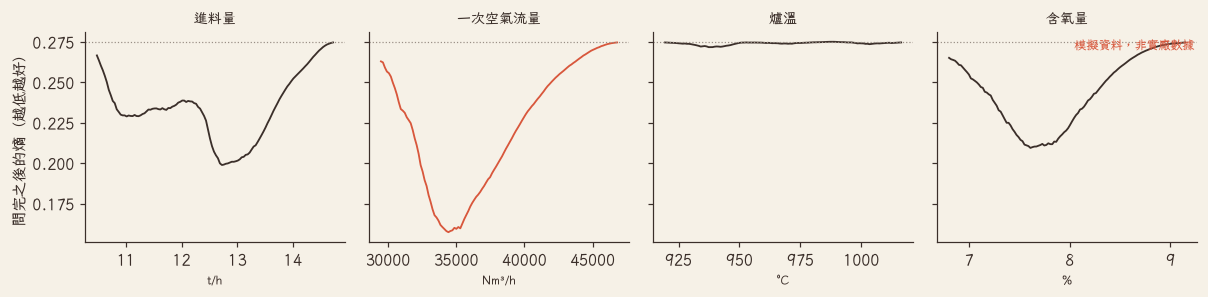

In [4]:
def ent(k, n):
    # 一群有 n 分鐘、其中 k 分鐘超過時的熵（自然對數）；可以一次算很多群
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = np.where(n > 0, k / np.maximum(n, 1), 0.0)
    with np.errstate(divide="ignore", invalid="ignore"):
        a = np.where(p > 0, p * np.log(p), 0.0)
        b = np.where(p < 1, (1 - p) * np.log(1 - p), 0.0)
    return -(a + b)

# 核對：熵 = 用這一群的比例去猜時的交叉熵
assert abs(ent(ytr.sum(), len(ytr)) - cross_entropy(ytr, np.full(len(ytr), ytr.mean()))) < 1e-9

MIN_LEAF = 1    # 每片葉子至少幾分鐘（和 scikit-learn 的預設一樣，不另外限制）

def scan_feature(Xs, ys, f, min_leaf=MIN_LEAF):
    # 一個感測器上，每一個切點問完之後的加權熵（總和，不是平均）
    n, k_all = len(ys), ys.sum()
    o = np.argsort(Xs[:, f], kind="stable"); xs, yo = Xs[o, f], ys[o]
    kL = np.cumsum(yo)[:-1]; nL = np.arange(1, n)
    ok = (xs[:-1] < xs[1:]) & (nL >= min_leaf) & (n - nL >= min_leaf)
    tot = nL * ent(kL, nL) + (n - nL) * ent(k_all - kL, n - nL)
    return (xs[:-1] + xs[1:]) / 2, np.where(ok, tot, np.inf)

def best_split(Xs, ys, min_leaf=MIN_LEAF):
    best = None
    for f in range(Xs.shape[1]):
        cut, tot = scan_feature(Xs, ys, f, min_leaf)
        i = int(np.argmin(tot))
        if np.isfinite(tot[i]) and (best is None or tot[i] < best[0] - 1e-9):
            best = (float(tot[i]), f, float(cut[i]))
    return best

root_H = float(ent(ytr.sum(), len(ytr)))
print(f"還沒問：訓練集的熵 {root_H:.3f}")
per_sensor = []
for f in range(4):
    cut, tot = scan_feature(Xtr, ytr, f)
    i = int(np.argmin(tot))
    per_sensor.append({"f": f, "name": NAMES[f], "thr": float(cut[i]), "H_after": float(tot[i] / len(ytr))})
    print(f"  只能問「{NAMES[f]}」：最好的切點 {cut[i]:,.3f} {UNITS[f]}，問完剩 {tot[i] / len(ytr):.3f}")
ROOT = best_split(Xtr, ytr)
print(f"\n第一題選：「{NAMES[ROOT[1]]} ≤ {ROOT[2]:,.1f} {UNITS[ROOT[1]]}？」熵從 {root_H:.3f} 降到 {ROOT[0] / len(ytr):.3f}"
      f"（少了 {100 * (1 - ROOT[0] / len(ytr) / root_H):.0f}%）")
# 核對：直接用遮罩算一次，和掃描的結果一樣
m = Xtr[:, ROOT[1]] <= ROOT[2]
assert abs((m.sum() * ent(ytr[m].sum(), m.sum()) + (~m).sum() * ent(ytr[~m].sum(), (~m).sum())) - ROOT[0]) < 1e-6
split_report(ROOT[1], ROOT[2])

fig, axs = plt.subplots(1, 4, figsize=(11, 2.8), sharey=True)
scan_curves = []
for f, ax in enumerate(axs):
    cut, tot = scan_feature(Xtr, ytr, f)
    good = np.isfinite(tot)
    lo, hi = np.percentile(Xtr[:, f], [0.5, 99.5])
    grid = np.linspace(lo, hi, 120)
    idx = np.clip(np.searchsorted(cut[good], grid), 0, good.sum() - 1)
    curve = (tot[good] / len(ytr))[idx]
    scan_curves.append({"f": f, "x": [round(float(v), 4) for v in grid], "H_after": [round(float(v), 5) for v in curve]})
    ax.plot(grid, curve, color=RED if f == ROOT[1] else INK, lw=1.2)
    ax.axhline(root_H, color=GREY, lw=0.8, ls=":")
    ax.set_title(NAMES[f], fontsize=9); ax.set_xlabel(UNITS[f], fontsize=8)
axs[0].set_ylabel("問完之後的熵（越低越好）"); tag(axs[-1]); plt.tight_layout(); plt.show()

## 4. 一直問下去：長出一棵樹
在「是」和「否」兩群裡，各自再用同一個規則挑下一題；一直分到：所有分鐘答案都一樣（熵 = 0）、分不動了，或到了最大深度。
最後每一片葉子給一個機率 = 這片葉子裡**訓練資料**超過警戒值的比例。

因為每一題都是照同一個規則、由上往下挑，「最深 d 層的樹」就是「很深的樹只留前 d 層」。所以先長一棵 20 層的樹，再截到不同深度來比較。

In [5]:
MAX_GROW = 20

def grow(Xs, ys, depth=0, max_depth=MAX_GROW, min_leaf=MIN_LEAF):
    n, k = len(ys), int(ys.sum())
    node = {"n": n, "k": k, "p": k / n, "depth": depth}
    if depth == max_depth or k == 0 or k == n or n < 2 * min_leaf:
        return node
    b = best_split(Xs, ys, min_leaf)
    if b is None or b[0] >= n * ent(k, n) - 1e-9:
        return node
    _, f, t = b
    m = Xs[:, f] <= t
    node.update(f=f, t=t, L=grow(Xs[m], ys[m], depth + 1, max_depth, min_leaf),
                R=grow(Xs[~m], ys[~m], depth + 1, max_depth, min_leaf))
    return node

def is_leaf(nd, dmax): return "f" not in nd or nd["depth"] >= dmax

def predict_tree(nd, Xs, dmax):
    out = np.empty(len(Xs))
    def go(n, idx):
        if is_leaf(n, dmax): out[idx] = n["p"]; return
        m = Xs[idx, n["f"]] <= n["t"]
        go(n["L"], idx[m]); go(n["R"], idx[~m])
    go(nd, np.arange(len(Xs)))
    return out

def leaves(nd, dmax, path=()):
    if is_leaf(nd, dmax): return [{"path": list(path), "n": nd["n"], "k": nd["k"], "p": nd["p"]}]
    return (leaves(nd["L"], dmax, path + ((nd["f"], "<=", nd["t"]),)) +
            leaves(nd["R"], dmax, path + ((nd["f"], ">", nd["t"]),)))

def print_tree(nd, dmax, ind=""):
    if is_leaf(nd, dmax):
        print(f"{ind}→ 葉子：{nd['n']:,} 分鐘，超過警戒值 {100 * nd['p']:.1f}%"); return
    print(f"{ind}{NAMES[nd['f']]} ≤ {nd['t']:,.2f} {UNITS[nd['f']]}？（{nd['n']:,} 分鐘，{100 * nd['p']:.1f}%）")
    print_tree(nd["L"], dmax, ind + "   是："); print_tree(nd["R"], dmax, ind + "   否：")

TREE = grow(Xtr, ytr)
assert TREE["f"] == ROOT[1] and abs(TREE["t"] - ROOT[2]) < 1e-9
print_tree(TREE, 3)
# 核對：訓練集上，樹的交叉熵 = 各葉子的熵照人數加權平均（樹挑問題時降的就是這個數）
for d in (1, 2, 3):
    lv = leaves(TREE, d)
    assert abs(sum(l["n"] * ent(l["k"], l["n"]) for l in lv) / len(ytr) - cross_entropy(ytr, predict_tree(TREE, Xtr, d))) < 1e-6

一次空氣流量 ≤ 34,472.89 Nm³/h？（14,340 分鐘，7.9%）
   是：進料量 ≤ 10.84 t/h？（2,794 分鐘，38.0%）
   是：   是：一次空氣流量 ≤ 33,333.03 Nm³/h？（393 分鐘，77.6%）
   是：   是：   是：→ 葉子：341 分鐘，超過警戒值 80.6%
   是：   是：   否：→ 葉子：52 分鐘，超過警戒值 57.7%
   是：   否：爐溫 ≤ 967.52 °C？（2,401 分鐘，31.5%）
   是：   否：   是：→ 葉子：1,470 分鐘，超過警戒值 14.0%
   是：   否：   否：→ 葉子：931 分鐘，超過警戒值 59.2%
   否：一次空氣流量 ≤ 36,914.39 Nm³/h？（11,546 分鐘，0.6%）
   否：   是：一次空氣流量 ≤ 35,304.13 Nm³/h？（2,048 分鐘，3.1%）
   否：   是：   是：→ 葉子：644 分鐘，超過警戒值 7.3%
   否：   是：   否：→ 葉子：1,404 分鐘，超過警戒值 1.1%
   否：   否：一次空氣流量 ≤ 37,355.58 Nm³/h？（9,498 分鐘，0.0%）
   否：   否：   是：→ 葉子：368 分鐘，超過警戒值 0.3%
   否：   否：   否：→ 葉子：9,130 分鐘，超過警戒值 0.0%


## 5. （Colab 才跑）和 scikit-learn 對照
scikit-learn 的 `DecisionTreeClassifier(criterion="entropy")` 用的是同一個想法。它內部把資料轉成 float32，切點可能有很小的差異，所以這裡只看：第一題問的感測器是否相同、切點差多少、兩層的樹在驗證集上給的機率有多少比例相同。本機沒有安裝 scikit-learn 時略過。

In [6]:
try:
    from sklearn.tree import DecisionTreeClassifier
    sk = DecisionTreeClassifier(criterion="entropy", max_depth=2, random_state=0).fit(Xtr, ytr)
    print(f"scikit-learn 第一題：{NAMES[sk.tree_.feature[0]]} ≤ {sk.tree_.threshold[0]:,.2f}（這本 notebook：{NAMES[TREE['f']]} ≤ {TREE['t']:,.2f}）")
    same = np.isclose(sk.predict_proba(Xva)[:, 1], predict_tree(TREE, Xva, 2), atol=1e-9).mean()
    print(f"兩層的樹在驗證集上給的機率，{100 * same:.2f}% 的分鐘完全相同")
except ImportError:
    print("（沒有安裝 scikit-learn，略過這個對照）")

（沒有安裝 scikit-learn，略過這個對照）


## 6. 樹太深會背答案：用驗證集選深度
樹越深，葉子越小，訓練集的交叉熵一路降到接近 0：很多葉子裡只剩一種答案，等於把訓練資料的答案背下來。
這種葉子給的機率是 0% 或 100%。到了沒看過的資料，只要錯一次，交叉熵就罰得很重（EP05：很有把握卻猜錯，罰最重）。

> **規則（只用驗證集）：深度 1–20 裡，驗證集交叉熵最小的深度；一樣小就取比較淺的。**

 深度  葉子數  訓練集交叉熵  驗證集交叉熵  訓練資料落在「只剩一種答案」葉子的比例
   1       2     0.157         0.360          0.0%
   2       4     0.139         0.314          0.0%
   3       8     0.118         0.365         63.7%
   4      15     0.104         0.399         66.2%
   5      27     0.090         0.903         74.7%
   6      43     0.080         1.203         77.1%
   7      69     0.072         1.326         81.2%
   8     105     0.063         1.684         84.4%
   9     148     0.054         1.957         86.5%
  10     197     0.045         2.332         88.4%
  11     238     0.038         2.480         89.9%
  12     280     0.031         2.628         92.6%
  13     316     0.023         2.817         94.0%
  14     347     0.017         2.916         96.4%
  15     367     0.014         3.022         97.5%
  16     387     0.010         3.083         98.2%
  17     402     0.008         3.138         98.6%
  18     418     0.005         3.156         99.1%
  19     432     0.003         3.208

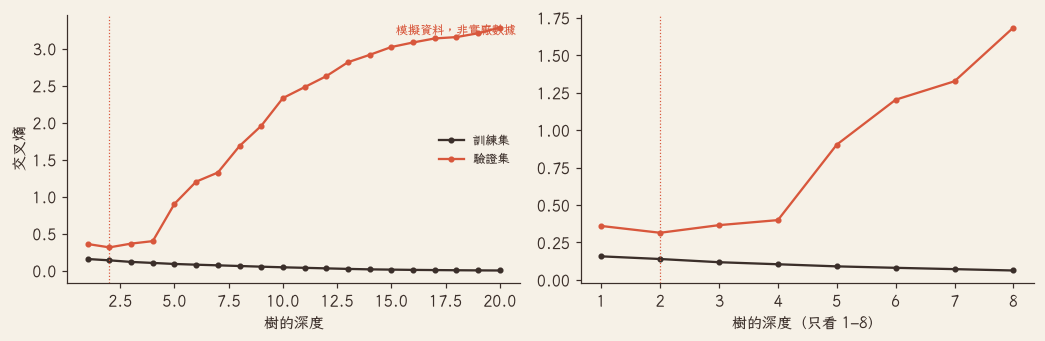

In [7]:
DEPTHS = list(range(1, MAX_GROW + 1))
depth_rows = []
for d in DEPTHS:
    ptr, pva = predict_tree(TREE, Xtr, d), predict_tree(TREE, Xva, d)
    lv = leaves(TREE, d)
    depth_rows.append({"depth": d, "leaves": len(lv), "ce_train": cross_entropy(ytr, ptr), "ce_val": cross_entropy(yva, pva),
                       "pure_leaf_share_train": sum(l["n"] for l in lv if l["k"] in (0, l["n"])) / len(ytr)})
print(" 深度  葉子數  訓練集交叉熵  驗證集交叉熵  訓練資料落在「只剩一種答案」葉子的比例")
for r in depth_rows:
    print(f"  {r['depth']:2d}   {r['leaves']:5d}     {r['ce_train']:.3f}        {r['ce_val']:6.3f}        {100 * r['pure_leaf_share_train']:5.1f}%")
best = min(depth_rows, key=lambda r: (round(r["ce_val"], 12), r["depth"]))
D_STAR = best["depth"]
print(f"\n選出的深度：{D_STAR}（{best['leaves']} 片葉子），驗證集交叉熵 {best['ce_val']:.3f}；EP05 的模型是 {cross_entropy(yva, p_lr_va):.3f}")
deep = depth_rows[-1]
print(f"對照：深度 {deep['depth']} 的樹，訓練集交叉熵 {deep['ce_train']:.3f}，驗證集 {deep['ce_val']:.3f}")

fig, axs = plt.subplots(1, 2, figsize=(9.6, 3.2))
axs[0].plot(DEPTHS, [r["ce_train"] for r in depth_rows], "o-", color=INK, ms=3, label="訓練集")
axs[0].plot(DEPTHS, [r["ce_val"] for r in depth_rows], "o-", color=RED, ms=3, label="驗證集")
axs[0].axvline(D_STAR, color=RED, lw=0.8, ls=":"); axs[0].set_xlabel("樹的深度"); axs[0].set_ylabel("交叉熵")
axs[0].legend(frameon=False, fontsize=8); tag(axs[0])
axs[1].plot(DEPTHS[:8], [r["ce_train"] for r in depth_rows[:8]], "o-", color=INK, ms=3)
axs[1].plot(DEPTHS[:8], [r["ce_val"] for r in depth_rows[:8]], "o-", color=RED, ms=3)
axs[1].axvline(D_STAR, color=RED, lw=0.8, ls=":"); axs[1].set_xlabel("樹的深度（只看 1–8）")
plt.tight_layout(); plt.show()

## 7. 讀得懂的規則
選出來的樹可以直接寫成幾行規則。葉子的機率 = 訓練資料裡落在這片葉子、超過警戒值的比例。

注意：**規則讀得懂，不代表它說的是原因。** 這組模擬資料裡，進料量、一次空氣流量、爐溫、含氧量彼此連動（EP05 notebook 第 7 段：權重的正負不能一個一個解讀）；樹先問哪一個感測器，是因為在這份訓練資料裡它最能把兩種分鐘分開，不代表它就是 CO 變高的原因。

一次空氣流量 ≤ 34,472.89 Nm³/h？（14,340 分鐘，7.9%）
   是：進料量 ≤ 10.84 t/h？（2,794 分鐘，38.0%）
   是：   是：→ 葉子：393 分鐘，超過警戒值 77.6%
   是：   否：→ 葉子：2,401 分鐘，超過警戒值 31.5%
   否：一次空氣流量 ≤ 36,914.39 Nm³/h？（11,546 分鐘，0.6%）
   否：   是：→ 葉子：2,048 分鐘，超過警戒值 3.1%
   否：   否：→ 葉子：9,498 分鐘，超過警戒值 0.0%
如果 一次空氣流量 ≤ 34,472.89 Nm³/h，而且 進料量 ≤ 10.84 t/h → 超過警戒值的機率 77.6%（訓練資料 393 分鐘）
如果 一次空氣流量 ≤ 34,472.89 Nm³/h，而且 進料量 > 10.84 t/h → 超過警戒值的機率 31.5%（訓練資料 2,401 分鐘）
如果 一次空氣流量 > 34,472.89 Nm³/h，而且 一次空氣流量 ≤ 36,914.39 Nm³/h → 超過警戒值的機率 3.1%（訓練資料 2,048 分鐘）
如果 一次空氣流量 > 34,472.89 Nm³/h，而且 一次空氣流量 > 36,914.39 Nm³/h → 超過警戒值的機率 0.0%（訓練資料 9,498 分鐘）

同樣的規則放到驗證集：葉子 1：1,117 分鐘，實際 69.7%；葉子 2：646 分鐘，實際 37.9%；葉子 3：1,601 分鐘，實際 6.6%；葉子 4：2,336 分鐘，實際 1.1%

EP05 的公式（標準化後的權重）： 進料量 -1.75、一次空氣流量 -2.23、爐溫 +1.47、含氧量 -0.37 ，截距 -6.62


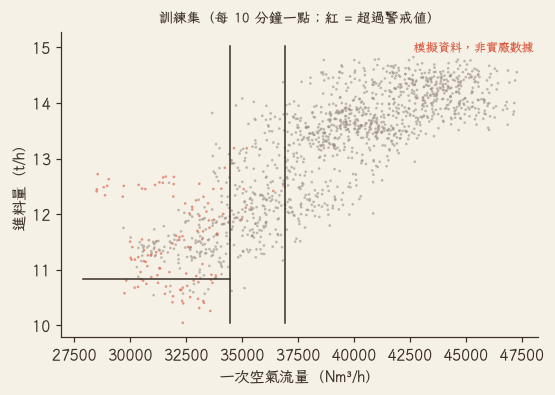

（圖上只畫得出問一次空氣流量或進料量的切線；選出的樹如果問了別的感測器，圖上看不到那一刀）


In [8]:
print_tree(TREE, D_STAR)
RULES = []
for l in leaves(TREE, D_STAR):
    conds = [f"{NAMES[f]} {'≤' if op == '<=' else '>'} {t:,.2f} {UNITS[f]}" for f, op, t in l["path"]]
    RULES.append({"conds": [{"f": int(f), "op": op, "t": round(float(t), 4)} for f, op, t in l["path"]],
                  "n": l["n"], "k": l["k"], "p": round(l["p"], 6)})
    print(f"如果 {'，而且 '.join(conds)} → 超過警戒值的機率 {100 * l['p']:.1f}%（訓練資料 {l['n']:,} 分鐘）")
lid_va = np.full(len(Xva), -1)
for i, r in enumerate(RULES):
    m = np.ones(len(Xva), bool)
    for c in r["conds"]:
        m &= (Xva[:, c["f"]] <= c["t"]) if c["op"] == "<=" else (Xva[:, c["f"]] > c["t"])
    lid_va[m] = i; r["val_n"] = int(m.sum()); r["val_rate"] = float(yva[m].mean()) if m.any() else None
assert (lid_va >= 0).all()
print("\n同樣的規則放到驗證集：" + "；".join(f"葉子 {i + 1}：{r['val_n']:,} 分鐘，實際 {100 * r['val_rate']:.1f}%" for i, r in enumerate(RULES)))
print("\nEP05 的公式（標準化後的權重）：", "、".join(f"{NAMES[i]} {W_EP05[i + 1]:+.2f}" for i in range(4)), f"，截距 {W_EP05[0]:+.2f}")

fig, ax = plt.subplots(figsize=(5.6, 3.6))
sub = np.arange(0, len(Xtr), 10)
ax.scatter(Xtr[sub, 1], Xtr[sub, 0], s=3, c=np.where(ytr[sub] == 1, RED, GREY), alpha=0.6, lw=0)
def draw_splits(nd, x0, x1, y0, y1, dmax):
    if is_leaf(nd, dmax): return
    if nd["f"] == 1:
        ax.plot([nd["t"]] * 2, [y0, y1], color=INK, lw=1); draw_splits(nd["L"], x0, nd["t"], y0, y1, dmax); draw_splits(nd["R"], nd["t"], x1, y0, y1, dmax)
    elif nd["f"] == 0:
        ax.plot([x0, x1], [nd["t"]] * 2, color=INK, lw=1); draw_splits(nd["L"], x0, x1, y0, nd["t"], dmax); draw_splits(nd["R"], x0, x1, nd["t"], y1, dmax)
xl, yl = (Xtr[:, 1].min(), Xtr[:, 1].max()), (Xtr[:, 0].min(), Xtr[:, 0].max())
draw_splits(TREE, *xl, *yl, D_STAR)
ax.set_xlabel("一次空氣流量（Nm³/h）"); ax.set_ylabel("進料量（t/h）"); ax.set_title("訓練集（每 10 分鐘一點；紅 = 超過警戒值）", fontsize=9)
tag(ax); plt.show()
print("（圖上只畫得出問一次空氣流量或進料量的切線；選出的樹如果問了別的感測器，圖上看不到那一刀）")

## 8. 用 EP06 的規則選門檻（樹和 EP05 的模型各選各的）
樹給的是機率，要不要響警報還是要一個門檻。用 EP06 同一條規則：**漏報 : 誤報 = 5 : 1（示意），驗證集上總代價最小的門檻（0.05–0.95，每 0.05 一格；一樣小取第一個）**。
EP05 的模型用同一條規則，應該選回 EP06 的 0.20。兩個模型唯一的差別就是模型本身。

In [9]:
COST_FN, COST_FP = 5.0, 1.0
THR_GRID = np.round(np.arange(0.05, 0.951, 0.05), 2)

def confusion(yv, alarm):
    yv, alarm = np.asarray(yv).astype(bool), np.asarray(alarm).astype(bool)
    return {"tp": int((yv & alarm).sum()), "fn": int((yv & ~alarm).sum()),
            "fp": int((~yv & alarm).sum()), "tn": int((~yv & ~alarm).sum())}

def scores(c):
    n = c["tp"] + c["fn"] + c["fp"] + c["tn"]
    prec = c["tp"] / (c["tp"] + c["fp"]) if (c["tp"] + c["fp"]) > 0 else None
    rec = c["tp"] / (c["tp"] + c["fn"]) if (c["tp"] + c["fn"]) > 0 else None
    return {"n": n, "accuracy": (c["tp"] + c["tn"]) / n, "precision": prec, "recall": rec,
            "alarm_share": (c["tp"] + c["fp"]) / n, "cost": COST_FN * c["fn"] + COST_FP * c["fp"]}

def pick_threshold(yv, p):
    rows = [{"thr": float(t), **confusion(yv, p >= t)} for t in THR_GRID]
    for r in rows: r["cost"] = COST_FN * r["fn"] + COST_FP * r["fp"]
    return min(rows, key=lambda r: r["cost"])["thr"], rows

p_tree_va = predict_tree(TREE, Xva, D_STAR)
T_TREE, sweep_tree = pick_threshold(yva, p_tree_va)
T_LR, sweep_lr = pick_threshold(yva, p_lr_va)
ep06 = Path("../v07-confusion-matrix/data/v07.json")
if ep06.exists():
    assert T_LR == json.loads(ep06.read_text(encoding="utf-8"))["lock"]["threshold"], "EP05 模型的門檻應該和 EP06 一樣"
tie = [r["thr"] for r in sweep_tree if r["cost"] == min(x["cost"] for x in sweep_tree)]
print(f"樹（深度 {D_STAR}）的門檻：{T_TREE:.2f}（總代價一樣小的門檻：{tie[0]:.2f}–{tie[-1]:.2f}）；EP05 的模型：{T_LR:.2f}")
alarm_leaves = [i + 1 for i, r in enumerate(RULES) if r["p"] >= T_TREE]
print(f"樹會響警報的葉子：{alarm_leaves}")
cm_tree_va, cm_lr_va = confusion(yva, p_tree_va >= T_TREE), confusion(yva, p_lr_va >= T_LR)
sc_tree_va, sc_lr_va = scores(cm_tree_va), scores(cm_lr_va)
for name, c, s in [("樹", cm_tree_va, sc_tree_va), ("EP05", cm_lr_va, sc_lr_va)]:
    print(f"驗證集 {name}：命中 {c['tp']:,} 漏報 {c['fn']:,} 誤報 {c['fp']:,} 正確不報 {c['tn']:,}｜"
          f"精確率 {s['precision']:.3f} 召回率 {s['recall']:.3f} 總代價 {s['cost']:,.0f}")

樹（深度 2）的門檻：0.05（總代價一樣小的門檻：0.05–0.30）；EP05 的模型：0.20
樹會響警報的葉子：[1, 2]
驗證集 樹：命中 1,024 漏報 132 誤報 739 正確不報 3,805｜精確率 0.581 召回率 0.886 總代價 1,399
驗證集 EP05：命中 995 漏報 161 誤報 505 正確不報 4,039｜精確率 0.663 召回率 0.861 總代價 1,310


## 9. 少一天資料，樹會不會變？
只用訓練集：拿掉最後一天（第 10 天），用同一個規則重長一棵同樣深度的樹，看問題有沒有變。第 9 天最後 60 分鐘的答案（接下來一小時的 CO 平均）會用到第 10 天的資料，所以這 60 分鐘也一起拿掉。

In [10]:
def describe(nd, dmax):
    if is_leaf(nd, dmax): return f"[{100 * nd['p']:.0f}%]"
    return f"{NAMES[nd['f']]}≤{nd['t']:,.1f}（是 {describe(nd['L'], dmax)}，否 {describe(nd['R'], dmax)}）"
TR9 = np.arange(0, 9 * 1440 - H)   # 第 9 天最後 60 分鐘的答案會看到第 10 天的 CO，所以也拿掉（和訓練集最後 60 分鐘的處理一樣）
TREE9 = grow(Xtr[TR9], ytr[TR9], max_depth=D_STAR)
print("第 1–10 天：", describe(TREE, D_STAR))
print("第 1–9 天： ", describe(TREE9, D_STAR))
def sig(nd, dmax):
    if is_leaf(nd, dmax): return ()
    return (nd["f"],) + sig(nd["L"], dmax) + sig(nd["R"], dmax)
STABLE = sig(TREE, D_STAR) == sig(TREE9, D_STAR)
print("問的感測器（照順序）一樣嗎？", "一樣" if STABLE else "不一樣")

第 1–10 天： 一次空氣流量≤34,472.9（是 進料量≤10.8（是 [78%]，否 [32%]），否 一次空氣流量≤36,914.4（是 [3%]，否 [0%]））
第 1–9 天：  一次空氣流量≤34,472.9（是 含氧量≤7.6（是 [53%]，否 [21%]），否 一次空氣流量≤36,916.0（是 [3%]，否 [0%]））
問的感測器（照順序）一樣嗎？ 不一樣


## 10. 鎖定設定（之後不再改）
- 樹：自己寫的決策樹（熵、每片葉子至少 1 分鐘），用第 1–10 天訓練，深度 = 第 6 段選出的值
- 門檻：第 8 段的規則在驗證集上選出的值（樹、EP05 的模型各一個）
- 對照組：EP05 的邏輯斯迴歸（權重不變），門檻照同一條規則
- 測試集：10 段 × 4 天 = 40 天（和 EP06 一樣長；EP06 第 7 段只看答案檢查過：超過警戒值的比例會隨時間飄動，一段 4 天常常幾乎沒有超過的案例，所以要 10 段），每段模擬 5 天丟掉第 1 天；種子從 2050 往上，超出模擬設定範圍的跳過並記下（只看感測器範圍，不看答案或分數）
- 要報告的（事先寫好）：兩個模型的交叉熵、混淆矩陣、準確率、精確率、召回率、總代價（5 : 1）；每一段的超過比例

In [11]:
LOCK = {"depth": D_STAR, "min_leaf": MIN_LEAF, "criterion": "entropy", "thr_tree": T_TREE, "thr_lr": T_LR,
        "rule_depth": "驗證集交叉熵最小（深度 1–20，一樣小取淺的）", "rule_thr": "驗證集總代價最小（漏報 : 誤報 = 5 : 1，0.05 一格）",
        "cost_fn": COST_FN, "cost_fp": COST_FP, "test_segments": 10, "test_days_per_segment": 4, "test_seed_from": 2050}
print(json.dumps(LOCK, ensure_ascii=False))

{"depth": 2, "min_leaf": 1, "criterion": "entropy", "thr_tree": 0.05, "thr_lr": 0.2, "rule_depth": "驗證集交叉熵最小（深度 1–20，一樣小取淺的）", "rule_thr": "驗證集總代價最小（漏報 : 誤報 = 5 : 1，0.05 一格）", "cost_fn": 5.0, "cost_fp": 1.0, "test_segments": 10, "test_days_per_segment": 4, "test_seed_from": 2050}


## 11. 測試集：全新的 40 天，只評估這一次

In [12]:
SEG = np.arange(1440, 5 * 1440 - H)
TEST_SEEDS, SKIPPED, segs = [], [], []
sd_ = LOCK["test_seed_from"]
while len(TEST_SEEDS) < LOCK["test_segments"]:
    try:
        raw_t, _, co_t = simulate(sd_, 5)
    except AssertionError:
        SKIPPED.append(sd_); sd_ += 1; continue
    Xt, _, yt_ = make_xy(raw_t, co_t)
    segs.append({"seed": sd_, "X": Xt[SEG], "y": yt_[SEG]})
    TEST_SEEDS.append(sd_); sd_ += 1
print(f"測試用的種子：{TEST_SEEDS}；超出模擬設定範圍而跳過的：{SKIPPED or '無'}")
Xte = np.concatenate([g["X"] for g in segs]); yte = np.concatenate([g["y"] for g in segs])
print(f"測試集 {len(yte):,} 分鐘，真的超過警戒值的有 {yte.sum():,} 分鐘（{100 * yte.mean():.1f}%）")
print("每一段的超過比例：", "、".join(f"{g['seed']}：{100 * g['y'].mean():.1f}%" for g in segs))

p_tree_te, p_lr_te = predict_tree(TREE, Xte, D_STAR), predict_lr(Xte)
test = {}
for key, name, p, t in [("tree", f"決策樹（深度 {D_STAR}）", p_tree_te, T_TREE), ("lr", "EP05 的邏輯斯迴歸", p_lr_te, T_LR)]:
    c = confusion(yte, p >= t); s = scores(c)
    test[key] = {"cm": c, "sc": s, "ce": cross_entropy(yte, p)}
    print(f"\n{name}，門檻 {t:.2f}\n  命中 {c['tp']:>6,}   漏報 {c['fn']:>6,}\n  誤報 {c['fp']:>6,}   正確不報 {c['tn']:>6,}"
          f"\n  交叉熵 {test[key]['ce']:.3f}  準確率 {s['accuracy']:.3f}  精確率 {s['precision']:.3f}  召回率 {s['recall']:.3f}  總代價 {s['cost']:,.0f}")
zero_leaf = [i for i, r in enumerate(RULES) if r["k"] == 0]
if zero_leaf:
    m0 = np.isin(predict_tree(TREE, Xte, D_STAR), [0.0])
    print(f"\n樹在測試集上：落在「訓練時一次都沒超過」葉子的 {m0.sum():,} 分鐘裡，有 {yte[m0].sum():,} 分鐘真的超過（模型說 0%）")

測試用的種子：[2050, 2051, 2052, 2053, 2054, 2055, 2056, 2057, 2058, 2059]；超出模擬設定範圍而跳過的：無
測試集 57,000 分鐘，真的超過警戒值的有 8,005 分鐘（14.0%）
每一段的超過比例： 2050：0.0%、2051：6.8%、2052：0.9%、2053：36.6%、2054：16.3%、2055：0.0%、2056：8.0%、2057：31.7%、2058：11.8%、2059：28.3%

決策樹（深度 2），門檻 0.05
  命中  7,650   漏報    355
  誤報 10,420   正確不報 38,575
  交叉熵 0.268  準確率 0.811  精確率 0.423  召回率 0.956  總代價 12,195

EP05 的邏輯斯迴歸，門檻 0.20
  命中  6,545   漏報  1,460
  誤報  5,503   正確不報 43,492
  交叉熵 0.212  準確率 0.878  精確率 0.543  召回率 0.818  總代價 12,803


## 12. 匯出資料給影片使用
影片（Remotion）讀這個 JSON 來畫圖。開場的金融機構臨櫃攔阻詐騙數字、1982 年胸痛流程圖的論文，都直接引自原始來源（見影片說明欄），不是這本 notebook 算的。

In [13]:
def r6(v): return None if v is None else round(float(v), 6)
def rs(d): return {k: (r6(v) if isinstance(v, float) else v) for k, v in d.items()}
def tree_json(nd, dmax):
    o = {"n": nd["n"], "k": nd["k"], "p": r6(nd["p"])}
    if not is_leaf(nd, dmax):
        o.update(f=int(nd["f"]), t=r6(nd["t"]), L=tree_json(nd["L"], dmax), R=tree_json(nd["R"], dmax))
    return o
sub = np.arange(0, len(Xtr), 10)
out = {
    "meta": {"names": NAMES, "units": UNITS, "thr_ppm": THR, "horizon_min": H, "unit": "分鐘", "n_train": int(len(TR)), "n_val": int(len(VA)),
             "test_seeds": TEST_SEEDS, "test_seeds_skipped": SKIPPED, "test_days": 4 * len(TEST_SEEDS), "n_test": int(len(yte)),
             "simulated": True, "label": LABEL},
    "lock": LOCK,
    "rates": {"train": r6(ytr.mean()), "val": r6(yva.mean()), "test": r6(yte.mean()),
              "test_segments": [{"seed": g["seed"], "rate": r6(g["y"].mean())} for g in segs]},
    "o2_demo": {"thr": 7.0, "yes_n": int((Xtr[:, 3] <= 7.0).sum()), "yes_rate": r6(ytr[Xtr[:, 3] <= 7.0].mean()),
                "no_n": int((Xtr[:, 3] > 7.0).sum()), "no_rate": r6(ytr[Xtr[:, 3] > 7.0].mean())},
    "root": {"H_before": r6(root_H), "f": int(ROOT[1]), "thr": r6(ROOT[2]), "H_after": r6(ROOT[0] / len(ytr)),
             "per_sensor": [rs(x) for x in per_sensor], "scan": scan_curves},
    "tree": tree_json(TREE, 3),
    "depth_curve": [rs(r) for r in depth_rows],
    "rules": RULES,
    "scatter_train": {"air": [round(float(v)) for v in Xtr[sub, 1]], "feed": [round(float(v), 2) for v in Xtr[sub, 0]], "y": [int(v) for v in ytr[sub]]},
    "val": {"ce_tree": r6(cross_entropy(yva, p_tree_va)), "ce_lr": r6(cross_entropy(yva, p_lr_va)),
            "cm_tree": cm_tree_va, "sc_tree": rs(sc_tree_va), "cm_lr": cm_lr_va, "sc_lr": rs(sc_lr_va),
            "thr_tie": [tie[0], tie[-1]], "alarm_leaves": alarm_leaves},
    "stability": {"days_1_10": describe(TREE, D_STAR), "days_1_9": describe(TREE9, D_STAR), "same_sensors": bool(STABLE),
                  "tree9": tree_json(TREE9, D_STAR)},
    "test": {k: {"cm": v["cm"], "sc": rs(v["sc"]), "ce": r6(v["ce"])} for k, v in test.items()},
}
Path("data").mkdir(exist_ok=True)
Path("data/v08.json").write_text(json.dumps(out, ensure_ascii=False), encoding="utf-8")
print(f"已匯出 data/v08.json（{Path('data/v08.json').stat().st_size / 1024:.0f} KB）")

已匯出 data/v08.json（39 KB）
